<a href="https://colab.research.google.com/github/FaizaTasneeem/apachejit-defect-prediction/blob/main/apachejit_defect_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ApacheJIT Just-In-Time Defect Prediction

## 1. Setup

In [14]:
# Install libraries not preinstalled in Colab (CatBoost, SHAP)
!pip install catboost shap

In [15]:
# Imports and output folder for saved figures
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

os.makedirs("figures", exist_ok=True)

## 2. Dataset

In [16]:
# Load ApacheJIT directly from the GitHub repo
url = "https://raw.githubusercontent.com/hosseinkshvrz/apachejit/master/dataset/apachejit_total.csv"
df = pd.read_csv(url)

### 2.1 Quick facts

In [17]:
# Basic overview: columns, number of rows, class balance, data type of each column
buggy = df[df['buggy'] == True]
print(f"Columns: {', ' .join(df.columns)}");
print(f"Row count: {len(df)}");
print(f"Share of buggy commits: {round((len(buggy)/len(df)*100), 2)} %");
print(df.dtypes)

Columns: commit_id, project, buggy, fix, year, author_date, la, ld, nf, nd, ns, ent, ndev, age, nuc, aexp, arexp, asexp
Row count: 106674
Share of buggy commits: 26.47 %
commit_id       object
project         object
buggy             bool
fix               bool
year             int64
author_date      int64
la               int64
ld               int64
nf               int64
nd               int64
ns               int64
ent            float64
ndev           float64
age            float64
nuc            float64
aexp             int64
arexp          float64
asexp          float64
dtype: object


In [18]:
# Convert Unix timestamp to datetime and show the date range
df["author_date"] = pd.to_datetime(df["author_date"], unit="s")
print("Earliest commit:", df["author_date"].min())
print("Latest commit:", df["author_date"].max())

Earliest commit: 2003-09-11 14:54:46
Latest commit: 2019-12-26 17:39:53


In [19]:
# Check whether rows are already in time order (needed for time-based split)
print("Checking if author_date is sorted in ascending order: ", df["author_date"].is_monotonic_increasing)
print("Checking if author_date is sorted in descending order: ", df["author_date"].is_monotonic_decreasing)

Checking if author_date is sorted in ascending order:  False
Checking if author_date is sorted in descending order:  False


In [20]:
# Missing values per column
print(df.isnull().sum())
print("Total missing:", df.isnull().sum().sum())

commit_id      0
project        0
buggy          0
fix            0
year           0
author_date    0
la             0
ld             0
nf             0
nd             0
ns             0
ent            0
ndev           0
age            0
nuc            0
aexp           0
arexp          0
asexp          0
dtype: int64
Total missing: 0


In [21]:
# Duplicate commits
print("Duplicate commit_ids:", df["commit_id"].duplicated().sum())

Duplicate commit_ids: 0


In [22]:
# Number of projects and commits per project
print("Number of project values:", df["project"].nunique())
print("Number of commits per project:", df["project"].value_counts())

Number of project values: 15
Number of commits per project: project
apache/camel               22700
apache/ignite              12036
apache/hadoop              11964
apache/flink               11691
apache/hbase                8730
apache/cassandra            8159
apache/groovy               8059
apache/hive                 6842
apache/activemq             6126
apache/hadoop-hdfs          2907
apache/kafka                2384
apache/spark                1465
apache/zeppelin             1451
apache/hadoop-mapreduce     1321
apache/zookeeper             839
Name: count, dtype: int64


## 3. Exploratory Data Analysis

### 3.1 Buggy vs clean: medians

In [23]:
# Median of each feature for buggy vs clean commits
features = ["la", "ld", "nf", "nd", "ns", "ent", "ndev", "age", "nuc", "aexp", "arexp", "asexp"]
medians = df.groupby("buggy")[features].median()
print(medians)

          la    ld   nf   nd   ns       ent  ndev        age        nuc  \
buggy                                                                     
False   22.0   6.0  2.0  2.0  1.0  0.918296   2.5  11.166667  13.000000   
True   138.0  27.0  6.0  3.0  1.0  1.768599   2.0  19.500000  22.614458   

        aexp  arexp  asexp  
buggy                       
False  241.0  191.0   52.0  
True   180.0  150.0    5.0  


### 3.2 Plots

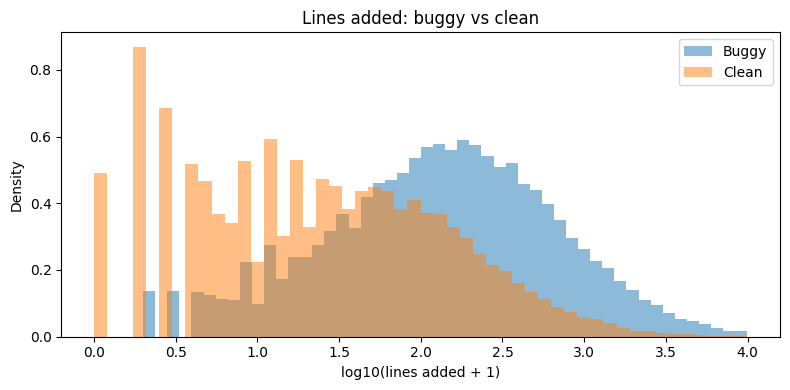

In [24]:
# Lines added, buggy vs clean (histogram)

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(np.log10(df.loc[df["buggy"], "la"] + 1),  bins=50, alpha=0.5, density=True, label="Buggy")
ax.hist(np.log10(df.loc[~df["buggy"], "la"] + 1), bins=50, alpha=0.5, density=True, label="Clean")

ax.set_title("Lines added: buggy vs clean");
ax.set_xlabel("log10(lines added + 1)");
ax.set_ylabel("Density")

ax.legend(); plt.tight_layout(); plt.savefig("figures/la_histogram.png", dpi=150); plt.show()


In [25]:
# Buggy rate per project (numbers behind the bar chart)
print(df.groupby("project")["buggy"].mean())

project
apache/activemq            0.229187
apache/camel               0.135595
apache/cassandra           0.382032
apache/flink               0.240441
apache/groovy              0.200273
apache/hadoop              0.000000
apache/hadoop-hdfs         0.764362
apache/hadoop-mapreduce    0.634368
apache/hbase               0.433219
apache/hive                0.617217
apache/ignite              0.202642
apache/kafka               0.467701
apache/spark               0.431399
apache/zeppelin            0.428670
apache/zookeeper           0.407628
Name: buggy, dtype: float64


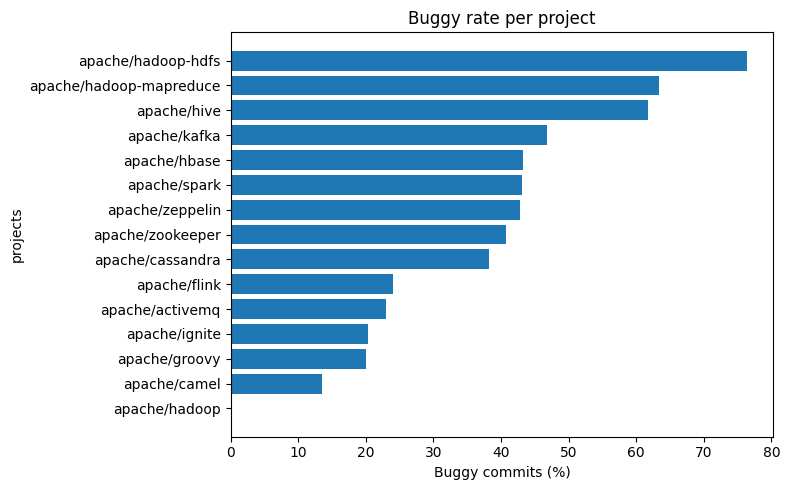

In [26]:
# Buggy rate per project (bar chart)

rate = df.groupby("project")["buggy"].mean().sort_values() * 100;

fig, ax = plt.subplots(figsize=(8, 5));

ax.barh(rate.index, rate.values);

ax.set_title("Buggy rate per project");
ax.set_xlabel("Buggy commits (%)");
ax.set_ylabel("projects");

plt.tight_layout(); plt.savefig("figures/buggy_rate_per_project.png", dpi=150); plt.show()

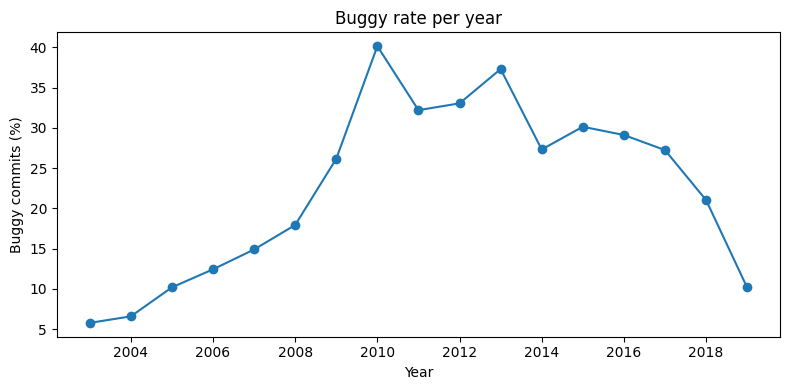

In [27]:
# Buggy rate per year (line plot)

yearly = df.groupby("year")["buggy"].mean() * 100;

fig, ax = plt.subplots(figsize=(8, 4));

ax.plot(yearly.index, yearly.values, marker="o");

ax.set_title("Buggy rate per year");
ax.set_xlabel("Year");
ax.set_ylabel("Buggy commits (%)");

plt.tight_layout(); plt.savefig("figures/buggy_rate_per_year.png", dpi=150); plt.show()

## 4. Method

### 4.1 Train / validation / test split

In [30]:
# Drop apache/hadoop (no buggy labels)

df = df[df["project"] != "apache/hadoop"]
print("Rows after dropping apache/hadoop:", len(df))

Rows after dropping apache/hadoop: 94710


In [31]:
# Sort by author_date

df = df.sort_values("author_date").reset_index(drop=True)
print("Sorted in ascending order:", df["author_date"].is_monotonic_increasing)

Sorted in ascending order: True


In [38]:
# Time-based split (70 / 15 / 15)

n = len(df)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

print("Train:", len(train), "| Validation:", len(val), "| Test:", len(test))
print("Total:", len(train) + len(val) + len(test), "(should equal", n, ")")

Train: 66297 | Validation: 14206 | Test: 14207
Total: 94710 (should equal 94710 )


In [44]:
# Check the split
for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} rows: {len(part):>6} | "
          f"{part['author_date'].min().date()} to {part['author_date'].max().date()} | "
          f"buggy: {part['buggy'].mean() * 100:.2f} %")

# Make sure the date ranges don't overlap
print("\nTrain ends before validation starts:", train["author_date"].max() <= val["author_date"].min())
print("Validation ends before test starts:  ", val["author_date"].max() <= test["author_date"].min())

Train       rows:  66297 | 2003-09-11 to 2016-07-26 | buggy: 32.04 %
Validation  rows:  14206 | 2016-07-26 to 2018-03-05 | buggy: 31.51 %
Test        rows:  14207 | 2018-03-05 to 2019-12-26 | buggy: 17.75 %

Train ends before validation starts: True
Validation ends before test starts:   True


In [45]:
# Separate features (X) and label (y)

feature_cols = ["la", "ld", "nf", "nd", "ns", "ent", "ndev", "age", "nuc",
                "aexp", "arexp", "asexp", "fix"]

X_train, y_train = train[feature_cols], train["buggy"]
X_val,   y_val   = val[feature_cols],   val["buggy"]
X_test,  y_test  = test[feature_cols],  test["buggy"]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

X_train: (66297, 13) | X_val: (14206, 13) | X_test: (14207, 13)


### 4.2 Preprocessing

In [ ]:
# Convert fix to 0/1

In [ ]:
# Log-transform skewed features

In [ ]:
# Scale features (fit on train only)

### 4.3 Baseline model: logistic regression

In [ ]:
# Train logistic regression (balanced class weights)

## Extras

In [28]:
# from google.colab import data_table

# start = 0
# data_table.DataTable(df.iloc[start:start + 20000], num_rows_per_page=50)

In [29]:
print(df.loc[df["buggy"], "la"])

12        213
16        223
52         63
64         52
79        792
         ... 
106641    355
106645    681
106654     60
106657      2
106669    605
Name: la, Length: 28239, dtype: int64
